# RAG Fitness & Nutrition : conception et évaluation d'un chatbot avec détection d'hallucinations

**Sujet 6 – Traitement Automatique du Langage Naturel (TALN)**  
**Filière : Intelligence Artificielle et Science des Données – 5ᵉ année**  
**Établissement : EMSI Rabat – Année universitaire 2026/2027**

**Réalisé par : Alae AZZAOUI et Saad BERRHOUT**

---

## Présentation du projet

Ce projet consiste à concevoir et évaluer un système conversationnel fondé sur l'architecture **Retrieval-Augmented Generation (RAG)**, spécialisé dans les domaines du fitness et de la nutrition.

L'objectif principal est de produire des réponses fiables, fondées exclusivement sur un corpus documentaire scientifique, tout en limitant les hallucinations grâce à un mécanisme de vérification basé sur l'**inférence en langage naturel (NLI)**.

Le notebook présente l'ensemble de la démarche expérimentale :

- Extraction et prétraitement des documents PDF.
- Comparaison de trois stratégies de segmentation (*Fixed-size, Recursive et Semantic Chunking*).
- Construction et comparaison des index vectoriels.
- Génération des réponses à l'aide de deux modèles de langage Qwen.
- Vérification des affirmations générées à l'aide d'un modèle NLI.
- Évaluation expérimentale sur un ensemble de 60 questions.
- Études d'ablation, analyse de sensibilité et analyse qualitative des erreurs.
- Validation du détecteur par comparaison avec des annotations humaines.

## Environnement d'exécution

Le projet a été exécuté sur **Kaggle Notebooks**, avec accélération GPU NVIDIA Tesla T4.

Les données sont chargées depuis le dataset Kaggle associé au notebook, tandis que les index vectoriels et les résultats expérimentaux sont stockés dans l'espace de travail `/kaggle/working/`.

**Configuration expérimentale :**
- Corpus documentaire : 20 fichiers PDF, soit 366 pages extraites.
- Questions d'évaluation : 60.
- Stratégies de segmentation : 3.
- Modèles génératifs : Qwen 2.5 (0.5B et 1.5B).
- Détecteur NLI : mDeBERTa-v3-base-mnli-xnli.
- Nombre de générations réalisées : 240.

## Reproductibilité

Les graines aléatoires sont fixées afin de favoriser la reproductibilité des expériences. La génération est configurée sans échantillonnage aléatoire.

Le notebook est organisé en cellules successives permettant de suivre les différentes étapes du pipeline, depuis la préparation du corpus jusqu'à l'évaluation des résultats.
# NB:  Le notebook Kaggle ne contient pas la totalité du travail. 
Le projet ne dispose d'aucun 
GPU local : seules les exécutions qui en exigent un (génération avec Qwen, inférence NLI) ont tourné sur 
Kaggle (GPU T4) et sont reprises dans le notebook. Tout le reste a été développé et exécuté en local, dans le 
dépôt GitHub : ingestion des PDF, découpage, indexation ChromaDB, correction des métriques sur les 
résultats exportés, export et analyse de la grille humaine, réglage du refus, constitution de data/sources.csv, 
intervalles de confiance et application Streamlit. Les chiffres de ce rapport ne se reproduisent donc qu'avec le 
notebook et le dépôt -> https://github.com/alaeazzaoui/rag-fitness-nutrition

In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/1550-2783-4-8.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/BJSM-IOC-consensus-statement-on-Relative-Energy-Deficiency-in-Sport-REDs.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/ISSN_Position_Stand_on_Creatine_2017.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/NUT-2025-VIG-0110.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/Nutrition for athletics.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/bjsports-2023-106807.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/fnut-06-00131.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/fphys-06-00245.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/fspor-04-949021.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/ijes-15-4-910.pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/main (2).pdf
/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition/nutrients-12-0202

## 1. Installation et configuration

In [3]:
from pathlib import Path

# Dataset Kaggle (lecture seule)
DATASET_DIR = Path("/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition")

# Dossier de travail (écriture autorisée)
PROJECT = Path("/kaggle/working/rag-fitness-nutrition")
PROJECT.mkdir(parents=True, exist_ok=True)

RAW_DIR = DATASET_DIR
QUESTIONS_FILE = DATASET_DIR / "questions.json"
RESULTS_DIR = PROJECT / "eval" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHROMA_DIR = "/kaggle/working/chroma_db"

print("Dataset :", DATASET_DIR.exists())
print("Questions :", QUESTIONS_FILE.exists())
print("PDF :", len(list(RAW_DIR.glob("*.pdf"))))

Dataset : True
Questions : True
PDF : 20


In [4]:
!pip install -q chromadb sentence-transformers transformers pymupdf langchain-text-splitters pandas matplotlib scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [5]:
import torch
import chromadb
import transformers
import sentence_transformers

print("GPU disponible :", torch.cuda.is_available())
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Installation OK")

GPU disponible : True
GPU : Tesla T4
Installation OK


In [20]:
import os, re, json, time, random, gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- Chemins (Kaggle) ----
DATASET_DIR = Path("/kaggle/input/datasets/alaeazzaoui/rag-fitness-nutrition")

PROJECT = Path("/kaggle/working/rag-fitness-nutrition")
RAW_DIR = DATASET_DIR
PROCESSED_DIR = PROJECT / "data" / "processed"
QUESTIONS_FILE = DATASET_DIR / "questions.json"
RESULTS_DIR = PROJECT / "eval" / "results"
CHROMA_DIR = "/kaggle/working/chroma_db"

for d in (PROCESSED_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
# ---- Paramètres expérimentaux ----
QUICK_MODE = False          # True : 5 questions par catégorie (20) ; False : les 60 questions
N_PER_CATEGORY = 5
TOP_K = 5
MAX_NEW_TOKENS = 300
RESUME = True              # reprend les résultats déjà sauvegardés sur Drive

EMBEDDINGS = {
    "minilm": "sentence-transformers/all-MiniLM-L6-v2",                      # base de référence
    "multi": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",  # ablation multilingue
}
BASE_EMB = "minilm"
COLLECTION_PLAN = [("fixed", "minilm"), ("recursive", "minilm"),
                   ("semantic", "minilm"), ("recursive", "multi")]

GENERATION_MODELS = {
    "Qwen 0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen 1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
}
# Configurations de génération : modèle -> stratégies de découpage testées
GRID = {
    "Qwen 0.5B": ["recursive"],
    "Qwen 1.5B": ["recursive", "fixed", "semantic"],
}

NLI_NAME = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
ENTAILMENT_THRESHOLD = 0.85
CONTRADICTION_THRESHOLD = 0.80
MIN_MARGIN = 0.15

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE)
if DEVICE == "cpu":
    # Mode CPU : configuration réduite pour rester exécutable (environ 30 à 40 minutes)
    GRID = {"Qwen 0.5B": ["recursive"], "Qwen 1.5B": ["recursive"]}
    N_PER_CATEGORY = 3
    MAX_NEW_TOKENS = 200
    print("Pas de GPU : configuration réduite (12 questions, découpage recursive pour la génération).")
    print("Le découpage et le modèle d'embeddings restent comparés sur le retrieval seul (section 5).")
assert RAW_DIR.exists(), f"Dossier introuvable : {RAW_DIR}"
assert QUESTIONS_FILE.exists(), f"Fichier introuvable : {QUESTIONS_FILE}"

Device : cuda


## 2. Corpus et origine des données

Le corpus documentaire utilisé dans ce projet est constitué de **20 fichiers PDF totalisant 366 pages**, portant principalement sur la nutrition sportive, les compléments alimentaires, la composition corporelle et l'entraînement en résistance.

Les documents proviennent de sources scientifiques et institutionnelles publiques, notamment :
- Les prises de position scientifiques de l'International Society of Sports Nutrition (ISSN).
- Des articles scientifiques publiés dans des revues en accès libre.
- Des publications et avis de l'Agence nationale de sécurité sanitaire de l'alimentation, de l'environnement et du travail (ANSES).

Chaque document est identifié par son nom de fichier. Cette organisation permet de conserver la traçabilité des sources et de rattacher les passages récupérés aux pages correspondantes, afin de faciliter la justification des réponses générées.

**Remarque :** les métadonnées bibliographiques détaillées (auteur, année de publication, URL et licence) restent à compléter dans un fichier dédié `sources.csv`.

In [7]:
import fitz  # PyMuPDF

pages = []
for pdf in sorted(RAW_DIR.glob("*.pdf")):
    with fitz.open(pdf) as doc:
        for i, page in enumerate(doc, start=1):
            text = page.get_text()
            if text.strip():
                pages.append({"source": pdf.name, "page": i, "text": text})

with open(PROCESSED_DIR / "documents.json", "w", encoding="utf-8") as f:
    json.dump(pages, f, ensure_ascii=False)

df_pages = pd.DataFrame(pages)
df_pages["chars"] = df_pages["text"].str.len()
sources_table = (df_pages.groupby("source")
                 .agg(pages=("page", "count"), caracteres=("chars", "sum"))
                 .reset_index())
print(f"{sources_table.shape[0]} PDF, {len(pages)} pages extraites")
display(sources_table)

sources_csv = PROJECT / "data" / "sources.csv"
if sources_csv.exists():
    display(pd.read_csv(sources_csv))
else:
    print("data/sources.csv absent : à ajouter (titre, auteur, année, URL, licence).")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


20 PDF, 366 pages extraites


,source,pages,caracteres
0,1550-2783-4-8.pdf,7,40976
1,BJSM-IOC-consensus-statement-on-Relative-Energ...,26,193018
2,ISSN_Position_Stand_on_Creatine_2017.pdf,18,108775
3,NUT-2025-VIG-0110.pdf,15,39198
4,Nutrition for athletics.pdf,1,5129
5,bjsports-2023-106807.pdf,12,70731
6,fnut-06-00131.pdf,15,100049
7,fphys-06-00245.pdf,9,59127
8,fspor-04-949021.pdf,12,70292
9,ijes-15-4-910.pdf,24,81822


data/sources.csv absent : à ajouter (titre, auteur, année, URL, licence).


## 3. Stratégies de découpage (*Chunking*)

Afin d'étudier l'influence de la segmentation sur les performances du système RAG, trois stratégies de découpage ont été comparées. Toutes sont appliquées **page par page**, afin de préserver le numéro de page associé à chaque segment et de garantir la traçabilité des sources.

1. **Fixed-size Chunking** : découpage du texte en segments de 500 caractères, avec un chevauchement de 100 caractères entre deux segments consécutifs.

2. **Recursive Chunking** : utilisation de `RecursiveCharacterTextSplitter` avec une taille cible de 500 caractères et un chevauchement de 100 caractères. Cette méthode privilégie les séparateurs hiérarchiques afin de préserver, autant que possible, la cohérence des paragraphes et des phrases.

3. **Semantic Chunking** : regroupement de phrases consécutives en fonction de leur similarité sémantique. Les segments sont constitués tant que la similarité reste supérieure ou égale à 0,65, dans la limite d'une taille maximale de 500 caractères et d'une taille minimale de 150 caractères.

In [8]:
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import RecursiveCharacterTextSplitter

embedders = {k: SentenceTransformer(v, device=DEVICE) for k, v in EMBEDDINGS.items()}

MIN_CHUNK_CHARS = 50

def fixed_chunks(pages, size=500, overlap=100):
    out, step = [], size - overlap
    for p in pages:
        text = " ".join(p["text"].split())
        for start in range(0, max(len(text), 1), step):
            piece = text[start:start + size]
            if len(piece.strip()) > MIN_CHUNK_CHARS:
                out.append({"source": p["source"], "page": p["page"], "text": piece})
            if start + size >= len(text):
                break
    return out

def recursive_chunks(pages, size=500, overlap=100):
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap)
    out = []
    for p in pages:
        for piece in splitter.split_text(p["text"]):
            piece = " ".join(piece.split())
            if len(piece) > MIN_CHUNK_CHARS:
                out.append({"source": p["source"], "page": p["page"], "text": piece})
    return out

def split_sentences(text):
    text = " ".join(text.split())
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]

def semantic_chunks(pages, embedder, threshold=0.65, max_len=500, min_len=150):
    out = []
    for p in pages:
        sents = split_sentences(p["text"])
        flat = []
        for s in sents:
            while len(s) > max_len:
                flat.append(s[:max_len]); s = s[max_len:]
            if s:
                flat.append(s)
        if not flat:
            continue
        embs = embedder.encode(flat, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
        current, pieces = flat[0], []
        for i in range(1, len(flat)):
            sim = float(np.dot(embs[i - 1], embs[i]))
            too_long = len(current) + 1 + len(flat[i]) > max_len
            topic_change = sim < threshold and len(current) >= min_len
            if too_long or topic_change:
                pieces.append(current); current = flat[i]
            else:
                current += " " + flat[i]
        pieces.append(current)
        for piece in pieces:
            if len(piece) > MIN_CHUNK_CHARS:
                out.append({"source": p["source"], "page": p["page"], "text": piece})
    return out

CHUNKS = {
    "fixed": fixed_chunks(pages),
    "recursive": recursive_chunks(pages),
    "semantic": semantic_chunks(pages, embedders[BASE_EMB]),
}

rows = []
for name, chunks in CHUNKS.items():
    lengths = [len(c["text"]) for c in chunks]
    rows.append({"stratégie": name, "chunks": len(chunks),
                 "longueur moyenne": round(float(np.mean(lengths)), 1),
                 "longueur min": min(lengths), "longueur max": max(lengths),
                 "documents couverts": len({c["source"] for c in chunks})})
chunk_stats = pd.DataFrame(rows)
display(chunk_stats)
chunk_stats.to_csv(RESULTS_DIR / "chunking_comparison.csv", index=False)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (17 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,stratégie,chunks,longueur moyenne,longueur min,longueur max,documents couverts
0,fixed,4858,484.5,101,500,20
1,recursive,4856,452.0,58,500,20
2,semantic,7935,238.9,51,500,20


## 4. Index vectoriel et recherche

Pour chaque stratégie de découpage, une collection vectorielle est construite à l'aide de **ChromaDB**, en utilisant la similarité cosinus comme mesure de comparaison. Le modèle d'embeddings de référence retenu est `all-MiniLM-L6-v2`.

Une collection supplémentaire est également créée à partir du découpage *Recursive*, en utilisant un modèle d'embeddings multilingue. Cette configuration permet d'étudier l'influence du modèle d'embeddings sur les performances de recherche, notamment dans un contexte multilingue où les questions sont formulées en français, tandis qu'une partie du corpus documentaire est rédigée en anglais.

In [9]:
import chromadb

client = chromadb.PersistentClient(path=CHROMA_DIR)
collections = {}

def build_collection(name, chunks, embedder):
    try:
        client.delete_collection(name)
    except Exception:
        pass
    col = client.create_collection(name=name, metadata={"hnsw:space": "cosine"})
    texts = [c["text"] for c in chunks]
    embs = embedder.encode(texts, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
    for i in range(0, len(chunks), 1000):
        j = min(i + 1000, len(chunks))
        col.add(ids=[f"{name}_{k}" for k in range(i, j)],
                embeddings=embs[i:j].tolist(),
                documents=texts[i:j],
                metadatas=[{"source": chunks[k]["source"], "page": chunks[k]["page"], "chunk_id": k}
                           for k in range(i, j)])
    return col

for strategy, emb_key in COLLECTION_PLAN:
    name = f"fitness_{strategy}_{emb_key}"
    collections[(strategy, emb_key)] = build_collection(name, CHUNKS[strategy], embedders[emb_key])
    print(f"{name}: {collections[(strategy, emb_key)].count()} vecteurs")

def retrieve(question, strategy, emb_key=BASE_EMB, k=TOP_K):
    col = collections[(strategy, emb_key)]
    q = embedders[emb_key].encode(question, normalize_embeddings=True).tolist()
    res = col.query(query_embeddings=[q], n_results=k, include=["documents", "metadatas", "distances"])
    return [{"content": d, "source": m["source"], "page": m["page"], "distance": float(dist)}
            for d, m, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0])]

fitness_fixed_minilm: 4858 vecteurs
fitness_recursive_minilm: 4856 vecteurs
fitness_semantic_minilm: 7935 vecteurs
fitness_recursive_multi: 4856 vecteurs


## 5. Jeu de questions et diagnostic du *Retrieval*

Le jeu d'évaluation est structuré autour de quatre catégories de questions :

- **Réponse présente** : la réponse peut être établie à partir du corpus documentaire.
- **Réponse absente** : les informations nécessaires ne sont pas disponibles dans le corpus ; un refus de réponse est donc attendu.
- **Question ambiguë** : la formulation ou le contexte ne permet pas d'identifier une réponse suffisamment précise.
- **Question multi-passages** : la réponse nécessite de combiner des informations issues de plusieurs passages documentaires.

Les questions portant le statut `removed` sont exclues de l'évaluation.

Les métriques de recherche fondées sur des passages de référence (`gold_sources`) sont calculées uniquement pour les questions pour lesquelles ces références ont été renseignées.

En complément, trois indicateurs de diagnostic indépendants des références sont utilisés :

1. **Proportion de passages en français** : permet d'identifier un éventuel biais linguistique du modèle d'embeddings.
2. **Proportion de passages assimilables à des listes de références bibliographiques** : repose sur une heuristique permettant de repérer la récupération de contenus de type bibliographique.
3. **Distance moyenne du passage le mieux classé** : fournit une indication sur la proximité entre la requête et le passage récupéré.

In [21]:
DEFAULT_BEHAVIOR = {"answer_present": "answer", "multi_passage": "answer",
                    "answer_absent": "refuse", "ambiguous": "clarify"}

with open(QUESTIONS_FILE, encoding="utf-8") as f:
    ALL_Q = [q for q in json.load(f)["questions"] if q.get("validation_status") != "removed"]

for q in ALL_Q:
    q["expected"] = q.get("expected_behavior") or DEFAULT_BEHAVIOR[q["category"]]

def select_questions(qs):
    if not QUICK_MODE:
        return qs
    by = {}
    for q in qs:
        by.setdefault(q["category"], []).append(q)
    sel = []
    for items in by.values():
        n = min(N_PER_CATEGORY, len(items))
        sel += [items[int(i * len(items) / n)] for i in range(n)]
    return sel

QUESTIONS = select_questions(ALL_Q)
QUESTION_IDS = {q["id"] for q in QUESTIONS}
n_gold = sum(1 for q in QUESTIONS if q.get("gold_sources"))
print(f"{len(QUESTIONS)} questions utilisées ({n_gold} avec passages de référence)")
display(pd.Series([q["category"] for q in QUESTIONS]).value_counts().rename("questions").to_frame())

FR_WORDS = [" le ", " la ", " les ", " des ", " une ", " est ", " pour ", " dans "]
EN_WORDS = [" the ", " of ", " and ", " with ", " that ", " is ", " for ", " in "]

def is_french(text):
    t = " " + text.lower() + " "
    return sum(t.count(w) for w in FR_WORDS) > sum(t.count(w) for w in EN_WORDS)

def looks_like_reference(text):
    return ("CrossRef" in text or text.count("doi") >= 2
            or re.search(r"\b(?:19|20)\d{2},\s*\d+,\s*\d+", text) is not None)

def gold_hit(q, passages):
    gold = q.get("gold_sources") or []
    if not gold:
        return None, None
    page_hit = any(str(p["source"]) == str(g["source"]) and str(p["page"]) == str(g["page"])
                   for p in passages for g in gold)
    doc_hit = any(str(p["source"]) == str(g["source"]) for p in passages for g in gold)
    return page_hit, doc_hit

answerable = [q for q in QUESTIONS if q["expected"] == "answer"]
rows = []
for (strategy, emb_key) in collections:
    fr, ref, dist, hits, dhits = [], [], [], [], []
    for q in answerable:
        ps = retrieve(q["question"], strategy, emb_key)
        fr.append(np.mean([is_french(p["content"]) for p in ps]))
        ref.append(np.mean([looks_like_reference(p["content"]) for p in ps]))
        dist.append(ps[0]["distance"])
        h, dh = gold_hit(q, ps)
        if h is not None:
            hits.append(h); dhits.append(dh)
    rows.append({"découpage": strategy, "embeddings": emb_key,
                 "% passages en français": round(100 * np.mean(fr), 1),
                 "% passages type références biblio": round(100 * np.mean(ref), 1),
                 "distance moyenne top-1": round(float(np.mean(dist)), 3),
                 f"hit@{TOP_K} page (n={len(hits)})": round(100 * np.mean(hits), 1) if hits else None,
                 f"hit@{TOP_K} document": round(100 * np.mean(dhits), 1) if dhits else None})
retrieval_table = pd.DataFrame(rows)
display(retrieval_table)
retrieval_table.to_csv(RESULTS_DIR / "retrieval_comparison.csv", index=False)

60 questions utilisées (0 avec passages de référence)


,questions
answer_present,20
answer_absent,15
multi_passage,15
ambiguous,10


,découpage,embeddings,% passages en français,% passages type références biblio,distance moyenne top-1,hit@5 page (n=0),hit@5 document
0,fixed,minilm,33.7,2.9,0.430,None,None
1,recursive,minilm,33.1,2.9,0.431,None,None
2,semantic,minilm,21.7,2.3,0.424,None,None
3,recursive,multi,0.0,3.4,0.231,None,None


## 6. Détecteur d'hallucinations basé sur le NLI

### Principe de fonctionnement

La réponse générée est d'abord décomposée en affirmations individuelles. Chaque affirmation est ensuite comparée aux passages récupérés à l'aide du modèle d'inférence en langage naturel (NLI) `mDeBERTa-v3-base-mnli-xnli`.

Pour chaque comparaison, le modèle attribue trois scores correspondant aux relations suivantes :

- **Entailment** : le passage apporte un soutien à l'affirmation.
- **Neutral** : le passage ne permet ni de confirmer ni de contredire l'affirmation.
- **Contradiction** : le passage contredit l'affirmation.

La classification finale repose sur les règles suivantes :

- `SUPPORTED` : le score maximal d'*entailment* est supérieur ou égal à **0,85**, avec une marge d'au moins **0,15** par rapport au score de contradiction.
- `CONTRADICTED` : le score maximal de *contradiction* est supérieur ou égal à **0,80**.
- `UNSUPPORTED` : aucune des conditions précédentes n'est satisfaite.

### Étude de la règle de négation

Une règle lexicale complémentaire a été testée afin de détecter certaines expressions négatives, telles que « ne… pas », « sans » ou « aucun ». Cette règle attribuait systématiquement le statut `UNSUPPORTED` aux affirmations concernées.

En raison de ce comportement trop restrictif, elle est désactivée dans la configuration principale et conservée uniquement dans le cadre de l'étude d'ablation. Les deux classifications sont néanmoins calculées à partir des mêmes scores NLI : `status` sans la règle et `status_negation_rule` avec son application.

### Ajustements méthodologiques

Deux corrections ont été apportées par rapport aux scripts initiaux :

- Les réponses de type refus ne sont pas considérées comme des affirmations à évaluer.
- Lorsqu'une réponse ne contient aucune affirmation évaluable, son score de fidélité est défini à `None`, plutôt qu'à 0 %.

### Limite du dispositif

Un score de fidélité élevé ne garantit pas nécessairement l'exactitude de la réponse. Le modèle NLI peut parfois identifier une proximité thématique entre une affirmation et un passage sans vérifier suffisamment la précision du contenu. Cette limite est notamment illustrée dans l'analyse qualitative des erreurs.

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

nli_tok = AutoTokenizer.from_pretrained(NLI_NAME)
nli_model = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(DEVICE).eval()
ID2LABEL = {i: l.lower() for i, l in nli_model.config.id2label.items()}
ENT_ID = next(i for i, l in ID2LABEL.items() if l == "entailment")
CON_ID = next(i for i, l in ID2LABEL.items() if l == "contradiction")
print("Labels NLI :", ID2LABEL)

def clean(text):
    return " ".join(text.split())

def split_into_claims(answer):
    if not answer:
        return []
    text = re.sub(r"\[S[\d,\sS]*\]", "", answer)
    claims = []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        line = re.sub(r"\*\*(.*?)\*\*", r"\1", line)
        line = re.sub(r"\*(.*?)\*", r"\1", line)
        line = re.sub(r"^\s*(?:[-*•]|\d+[.)])\s*", "", line)
        for sentence in re.split(r"(?<=[.!?])\s+", line):
            sentence = sentence.strip()
            if len(sentence.split()) < 5 or sentence[-1] not in ".!?":
                continue
            claims.append(sentence)
    return claims

NEGATION_PATTERNS = [r"\bne\b.*\bpas\b", r"\bn['’]est pas\b", r"\bpas systématiquement\b",
                     r"\bpas nécessairement\b", r"\bni\b", r"\baucun(?:e)?\b",
                     r"\babsence de\b", r"\bsans\b", r"\bnon observé\b", r"\bnon démontré\b"]

def has_negation_conflict(claim, passages):
    words = lambda s: {w.lower() for w in re.findall(r"\b[a-zA-ZÀ-ÿ]{5,}\b", s)}
    claim_words = words(claim)
    for passage in passages:
        for sentence in re.split(r"(?<=[.!?])\s+", passage["content"]):
            if claim_words & words(sentence) and any(
                    re.search(p, sentence.lower()) for p in NEGATION_PATTERNS):
                return True
    return False

def nli_scores_batch(claim, passages):
    premises = [clean(p["content"]) for p in passages]
    inputs = nli_tok(premises, [clean(claim)] * len(premises), return_tensors="pt",
                     truncation=True, max_length=512, padding=True).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(nli_model(**inputs).logits, dim=1).cpu().numpy()
    return probs[:, ENT_ID], probs[:, CON_ID]

def classify(best_ent, best_con, negation, use_rule=False,
             ent_th=None, con_th=None, margin=None):
    ent_th = ENTAILMENT_THRESHOLD if ent_th is None else ent_th
    con_th = CONTRADICTION_THRESHOLD if con_th is None else con_th
    margin = MIN_MARGIN if margin is None else margin
    if best_con >= con_th:
        return "CONTRADICTED"
    if best_ent >= ent_th and best_ent - best_con >= margin and not (use_rule and negation):
        return "SUPPORTED"
    return "UNSUPPORTED"

def check_claim(claim, passages):
    ent, con = nli_scores_batch(claim, passages)
    i = int(np.argmax(ent))
    best_ent, best_con = float(ent[i]), float(con.max())
    neg = has_negation_conflict(claim, passages)
    return {"text": claim,
            "status": classify(best_ent, best_con, neg, use_rule=False),
            "status_negation_rule": classify(best_ent, best_con, neg, use_rule=True),
            "best_entailment": round(best_ent, 4),
            "max_contradiction": round(best_con, 4),
            "negation_detected": neg,
            "evidence": {"source": passages[i]["source"], "page": passages[i]["page"],
                         "text": clean(passages[i]["content"])[:400]}}

def faithfulness(claims, key="status"):
    if not claims:
        return None
    return 100.0 * sum(c[key] == "SUPPORTED" for c in claims) / len(claims)

print("Détecteur prêt.")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Labels NLI : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
Détecteur prêt.


## 7. Génération des réponses avec citations et mécanisme de refus

La génération des réponses repose sur un prompt conçu pour garantir leur fidélité au corpus documentaire. Celui-ci impose au modèle de respecter trois règles principales :

- Produire des réponses exclusivement à partir des passages récupérés, sans ajouter d'informations externes.
- Associer les informations utilisées à leurs sources respectives, à l'aide de références au format `[S1]`, `[S2]`, etc.
- Utiliser une phrase de refus prédéfinie lorsque les documents disponibles ne permettent pas de répondre à la question.

La détection des refus repose sur l'identification de cette phrase prédéfinie dans la réponse générée.

Deux modèles de langage ouverts sont comparés : `Qwen2.5-0.5B-Instruct` et `Qwen2.5-1.5B-Instruct`. La génération est réalisée de manière déterministe afin de favoriser la reproductibilité des expériences.

Enfin, le paramètre `MAX_NEW_TOKENS` a été augmenté de **200 à 300** par rapport aux essais préliminaires, dans le but de réduire les risques de troncature des réponses. Les réponses qui demeurent incomplètes sont signalées afin d'être prises en compte lors de l'analyse des résultats.

In [15]:
from transformers import AutoModelForCausalLM

REFUSAL_PHRASE = "Je ne dispose pas d'informations suffisantes dans les documents pour répondre à cette question."
REFUSAL_MARKER = "ne dispose pas d'informations suffisantes"

def build_prompt(question, passages):
    context = ""
    for i, p in enumerate(passages, start=1):
        context += f"\n[S{i}] Source: {p['source']}, Page: {p['page']}\n{clean(p['content'])}\n"
    return f"""Tu es un assistant spécialisé en nutrition et activité physique.

Ta mission est de répondre à la question en utilisant exclusivement les documents fournis.

RÈGLES OBLIGATOIRES :
1. Utilise uniquement les informations des documents.
2. N'invente aucune information.
3. Ne complète pas les informations avec tes connaissances personnelles.
4. Cite les sources avec [S1], [S2], etc.
5. Si les documents ne permettent pas de répondre, réponds exactement :
   "{REFUSAL_PHRASE}"
6. Ne formule pas de recommandations médicales personnalisées.
7. Réponds en français.
8. Sois précis et concis.
9. N'ajoute aucun chiffre ou effet absent des documents.
10. Ne présente pas une hypothèse comme un fait établi.

DOCUMENTS :
{context}

QUESTION :
{question}

RÉPONSE :
"""

def load_generation_model(name):
    tok = AutoTokenizer.from_pretrained(name)
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype).to(DEVICE).eval()
    return tok, model

def generate_answer(question, passages, tok, model):
    messages = [{"role": "user", "content": build_prompt(question, passages)}]
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(DEVICE)
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             repetition_penalty=1.1, pad_token_id=tok.eos_token_id)
    elapsed = time.time() - t0
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    answer = tok.decode(new_tokens, skip_special_tokens=True).strip()
    return answer, elapsed, len(new_tokens)

def is_refusal(answer):
    return REFUSAL_MARKER in answer.lower().replace("’", "'")

def has_citation(answer):
    return re.search(r"\[S\d+", answer) is not None

## 8. Protocole expérimental

Pour chaque configuration expérimentale, définie par une combinaison de modèle génératif et de stratégie de découpage, les étapes suivantes sont exécutées pour chacune des questions du jeu d'évaluation :

1. **Retrieval** : recherche des passages documentaires les plus pertinents.
2. **Génération** : production d'une réponse à partir des passages récupérés.
3. **Détection des refus** : identification des réponses contenant la phrase de refus prédéfinie.
4. **Évaluation NLI** : décomposition des réponses en affirmations, puis vérification de leur cohérence avec les passages récupérés.

Les résultats sont sauvegardés sur Google Drive à la fin de chaque lot afin de limiter les pertes de données en cas d'interruption.

Le mécanisme de reprise, activé par le paramètre `RESUME = True`, permet de poursuivre l'exécution à partir du dernier lot traité, sans devoir recommencer les expériences déjà réalisées.

In [22]:
RESULTS_FILE = RESULTS_DIR / "notebook_results.json"

records = []
if RESUME and RESULTS_FILE.exists():
    with open(RESULTS_FILE, encoding="utf-8") as f:
        records = json.load(f)
done = {(r["model"], r["strategy"], r["id"]) for r in records}
print(f"{len(records)} résultats déjà présents")

def save_records():
    with open(RESULTS_FILE, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=1)

for model_label, strategies in GRID.items():
    todo = [(s, q) for s in strategies for q in QUESTIONS
            if (model_label, s, q["id"]) not in done]
    if not todo:
        continue
    print(f"\n=== {model_label} : {len(todo)} générations ===")
    tok, model = load_generation_model(GENERATION_MODELS[model_label])

    for n, (strategy, q) in enumerate(todo, start=1):
        passages = retrieve(q["question"], strategy)
        answer, g_time, n_tokens = generate_answer(q["question"], passages, tok, model)
        refused = is_refusal(answer)

        t0 = time.time()
        claims = [] if refused else [check_claim(c, passages) for c in split_into_claims(answer)]
        nli_time = time.time() - t0

        page_hit, doc_hit = gold_hit(q, passages)
        records.append({
            "id": q["id"], "category": q["category"], "expected": q["expected"],
            "question": q["question"], "model": model_label, "strategy": strategy,
            "answer": answer, "refused": refused, "has_citation": has_citation(answer),
            "truncated": n_tokens >= MAX_NEW_TOKENS,
            "generation_time": round(g_time, 2), "nli_time": round(nli_time, 2),
            "n_claims": len(claims), "claims": claims,
            "retrieval_page_hit": page_hit, "retrieval_doc_hit": doc_hit,
            "top_sources": [(p["source"], p["page"]) for p in passages],
        })
        if n % 10 == 0:
            save_records()
            print(f"  {n}/{len(todo)}")

    save_records()
    del model, tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nTerminé. Résultats :", RESULTS_FILE)

80 résultats déjà présents

=== Qwen 0.5B : 40 générations ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  10/40
  20/40
  30/40
  40/40

=== Qwen 1.5B : 120 générations ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  10/120
  20/120
  30/120
  40/120
  50/120
  60/120
  70/120
  80/120
  90/120
  100/120
  110/120
  120/120

Terminé. Résultats : /kaggle/working/rag-fitness-nutrition/eval/results/notebook_results.json


## 9. Résultats

In [23]:
df = pd.DataFrame(records)
df = df[df["id"].isin(QUESTION_IDS)].copy()
df["faith"] = df["claims"].apply(lambda c: faithfulness(c, "status"))
df["faith_rule"] = df["claims"].apply(lambda c: faithfulness(c, "status_negation_rule"))

def behavior_ok(r):
    if r["expected"] == "refuse":
        return r["refused"]
    if r["expected"] == "answer":
        return not r["refused"]
    return None          # "clarify" : à juger manuellement

df["behavior_ok"] = df.apply(behavior_ok, axis=1)

def summarize(g):
    answered = g[~g["refused"]]
    return pd.Series({
        "questions": len(g),
        "fidélité moyenne (%)": round(answered["faith"].mean(), 1),
        "contradictions (affirmations)": int(sum(c["status"] == "CONTRADICTED"
                                                 for cl in g["claims"] for c in cl)),
        "citations [S#] (%)": round(100 * answered["has_citation"].mean(), 1) if len(answered) else None,
        "réponses tronquées (%)": round(100 * g["truncated"].mean(), 1),
        "comportement attendu respecté (%)": round(100 * g["behavior_ok"].dropna().astype(float).mean(), 1),
        "temps génération (s)": round(g["generation_time"].mean(), 1),
        "temps NLI (s)": round(g["nli_time"].mean(), 2),
    })

summary = df.groupby(["model", "strategy"]).apply(summarize).reset_index()
display(summary)
summary.to_csv(RESULTS_DIR / "summary_by_config.csv", index=False)

by_cat = (df.groupby(["model", "strategy", "category"])
          .agg(questions=("id", "count"),
               taux_de_refus=("refused", "mean"),
               fidélité=("faith", "mean"))
          .round(2).reset_index())
display(by_cat)
by_cat.to_csv(RESULTS_DIR / "summary_by_category.csv", index=False)

/tmp/ipykernel_49/1363856244.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df.groupby(["model", "strategy"]).apply(summarize).reset_index()


,model,strategy,questions,fidélité moyenne (%),contradictions (affirmations),citations [S#] (%),réponses tronquées (%),comportement attendu respecté (%),temps génération (s),temps NLI (s)
0,Qwen 0.5B,recursive,60.0,10.4,11.0,0.0,41.7,84.0,5.9,0.13
1,Qwen 1.5B,fixed,60.0,16.8,18.0,10.0,36.7,90.0,7.8,0.14
2,Qwen 1.5B,recursive,60.0,12.3,24.0,0.0,36.7,86.0,7.9,0.13
3,Qwen 1.5B,semantic,60.0,17.2,19.0,12.0,30.0,90.0,7.3,0.10


,model,strategy,category,questions,taux_de_refus,fidélité
0,Qwen 0.5B,recursive,ambiguous,10,0.40,10.00
1,Qwen 0.5B,recursive,answer_absent,15,0.53,7.14
2,Qwen 0.5B,recursive,answer_present,20,0.05,15.77
3,Qwen 0.5B,recursive,multi_passage,15,0.00,5.75
4,Qwen 1.5B,fixed,ambiguous,10,0.00,16.67
5,Qwen 1.5B,fixed,answer_absent,15,0.67,9.17
6,Qwen 1.5B,fixed,answer_present,20,0.00,26.58
7,Qwen 1.5B,fixed,multi_passage,15,0.00,6.30
8,Qwen 1.5B,recursive,ambiguous,10,0.00,9.50
9,Qwen 1.5B,recursive,answer_absent,15,0.53,5.61


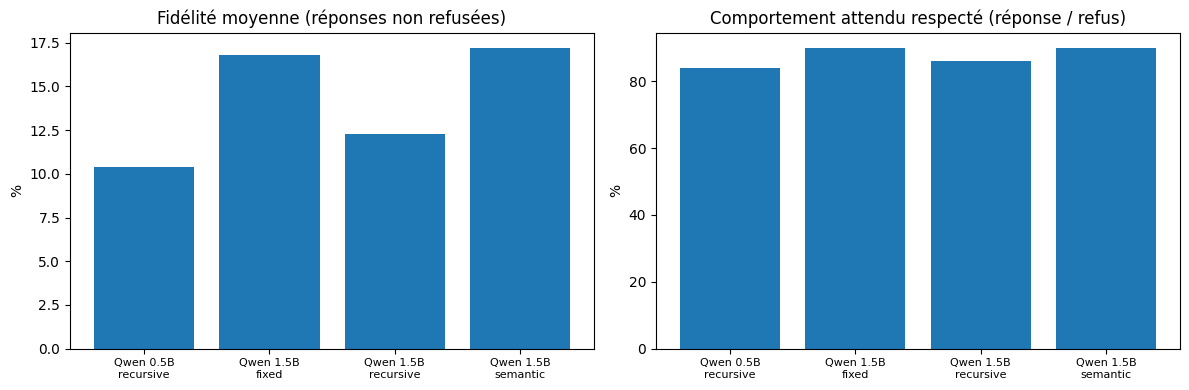

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [f"{m}\n{s}" for m, s in zip(summary["model"], summary["strategy"])]

axes[0].bar(labels, summary["fidélité moyenne (%)"])
axes[0].set_title("Fidélité moyenne (réponses non refusées)")
axes[0].set_ylabel("%")

axes[1].bar(labels, summary["comportement attendu respecté (%)"])
axes[1].set_title("Comportement attendu respecté (réponse / refus)")
axes[1].set_ylabel("%")

for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "results_overview.png", dpi=150)
plt.show()

## 10. Études d'ablation et analyse de sensibilité

Plusieurs expériences complémentaires ont été menées afin d'évaluer l'influence des différents composants du système sur ses performances.

1. **Stratégies de découpage** : comparaison des trois méthodes (*Fixed-size, Recursive et Semantic Chunking*) en maintenant le même modèle génératif. Les résultats sont présentés dans le tableau de la section 9 et complétés par le diagnostic du *retrieval* (section 5).

2. **Modèle d'embeddings** : comparaison du modèle `all-MiniLM-L6-v2` avec un modèle multilingue, afin d'évaluer leur influence sur les performances de recherche documentaire (section 5).

3. **Règle de négation** : étude de son impact sur le score de fidélité en comparant les résultats obtenus avec et sans son application, à partir des mêmes scores NLI.

4. **Seuil d'entailment** : analyse de la sensibilité du score de fidélité aux variations du seuil minimal requis pour considérer une affirmation comme soutenue par les passages récupérés.

Ablation : règle de négation (fidélité moyenne, %)


,model,strategy,sans_regle,avec_regle
0,Qwen 0.5B,recursive,10.4,10.4
1,Qwen 1.5B,fixed,16.8,14.9
2,Qwen 1.5B,recursive,12.3,11.4
3,Qwen 1.5B,semantic,17.2,16.0


seuil                0.50  0.70  0.85  0.95  0.99
model     strategy                               
Qwen 0.5B recursive  14.8  12.5  10.4   8.9   3.0
Qwen 1.5B fixed      21.0  18.8  16.8  14.7  11.7
          recursive  15.6  13.7  12.3   9.7   6.4
          semantic   22.6  22.1  17.2  14.4   9.8

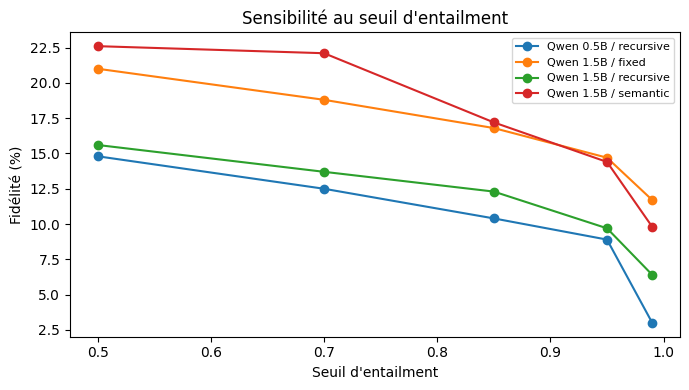

In [25]:
abl = (df.groupby(["model", "strategy"])
       .agg(sans_regle=("faith", "mean"), avec_regle=("faith_rule", "mean"))
       .round(1).reset_index())
print("Ablation : règle de négation (fidélité moyenne, %)")
display(abl)
abl.to_csv(RESULTS_DIR / "ablation_negation_rule.csv", index=False)

THRESHOLDS = [0.50, 0.70, 0.85, 0.95, 0.99]
rows = []
for (model, strategy), g in df.groupby(["model", "strategy"]):
    for th in THRESHOLDS:
        vals = []
        for claims in g["claims"]:
            if not claims:
                continue
            st = [classify(c["best_entailment"], c["max_contradiction"],
                           c["negation_detected"], use_rule=False, ent_th=th)
                  for c in claims]
            vals.append(100.0 * sum(s == "SUPPORTED" for s in st) / len(st))
        rows.append({"model": model, "strategy": strategy, "seuil": th,
                     "fidélité (%)": round(float(np.mean(vals)), 1) if vals else None})
sens = pd.DataFrame(rows)
display(sens.pivot_table(index=["model", "strategy"], columns="seuil", values="fidélité (%)"))
sens.to_csv(RESULTS_DIR / "ablation_entailment_threshold.csv", index=False)

plt.figure(figsize=(7, 4))
for (model, strategy), g in sens.groupby(["model", "strategy"]):
    plt.plot(g["seuil"], g["fidélité (%)"], marker="o", label=f"{model} / {strategy}")
plt.xlabel("Seuil d'entailment"); plt.ylabel("Fidélité (%)")
plt.title("Sensibilité au seuil d'entailment"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "sensitivity_threshold.png", dpi=150); plt.show()

## 11. Analyse qualitative des erreurs

Cette section présente des exemples concrets d'erreurs observées au cours des expérimentations afin d'identifier les limites du système.

L'analyse porte sur les différentes catégories d'erreurs et cherche à déterminer leur origine probable parmi les trois composantes principales du pipeline :

- **Retrieval** : récupération de passages insuffisamment pertinents ou ne contenant pas les informations nécessaires.
- **Génération** : production d'affirmations incorrectes, non justifiées ou insuffisamment fidèles aux sources.
- **Détecteur NLI** : classification incorrecte des affirmations, notamment lorsqu'il confond proximité thématique et véritable soutien documentaire.

Les exemples présentés dans les cellules suivantes serviront de base à une discussion critique des résultats dans l'article, en mettant en évidence les causes probables de chaque catégorie d'erreur.

In [26]:
base = df[(df["model"] == "Qwen 1.5B") & (df["strategy"] == "recursive")]

print("=== A. Refus attendu mais le modèle a répondu ===")
for _, r in base[(base["expected"] == "refuse") & (~base["refused"])].head(5).iterrows():
    print(f"\n[{r['id']}] {r['question']}\n  -> {r['answer'][:350]}")

print("\n\n=== B. Réponse attendue mais le modèle a refusé ===")
for _, r in base[(base["expected"] == "answer") & (base["refused"])].head(5).iterrows():
    print(f"\n[{r['id']}] {r['question']}\n  sources récupérées : {r['top_sources'][:3]}")

=== A. Refus attendu mais le modèle a répondu ===

[Q21] Quel est le meilleur complément alimentaire pour gagner exactement 5 kg de muscle en 30 jours ?
  -> Selon les informations fournies dans les documents, il n'y a pas de complément alimentaire spécifique mentionné qui serait idéal pour gagner exactement 5 kg de muscle en 30 jours. Les documents soulignent plutôt que la consommation de protéines apporte une contribution significative à la croissance musculaire, mais ils ne donnent pas de conseils sp

[Q24] Combien de calories exactes dois-je consommer chaque jour selon mon poids et mon âge ?
  -> Selon les données fournies dans le document S4, vous consommez actuellement 140 grammes de protéines par jour, ce qui correspond à environ 1,6 grammes de protéines par kilogramme de poids corporel par jour. 

Pour calculer votre calorie nécessaire journalière, nous devons prendre en compte plusieurs facteurs tels que votre taux de rétention caloriq

[Q33] Quel est le diagnostic médical d'u

In [27]:
print("=== C. Affirmations rejetées avec un entailment très faible (hallucinations probables) ===")
shown = 0
for _, r in base.iterrows():
    for c in r["claims"]:
        if c["status"] != "SUPPORTED" and c["best_entailment"] < 0.1 and shown < 6:
            print(f"\n[{r['id']}] {c['text']}\n  entailment={c['best_entailment']} | "
                  f"preuve la plus proche : {c['evidence']['source']} p.{c['evidence']['page']}")
            shown += 1

print("\n\n=== D. Affirmations validées à contrôler à la main (faux positifs possibles) ===")
shown = 0
for _, r in base.iterrows():
    for c in r["claims"]:
        if c["status"] == "SUPPORTED" and shown < 6:
            print(f"\n[{r['id']}] AFFIRMATION : {c['text']}\n  PREUVE ({c['evidence']['source']} "
                  f"p.{c['evidence']['page']}) : {c['evidence']['text'][:250]}...")
            shown += 1

=== C. Affirmations rejetées avec un entailment très faible (hallucinations probables) ===

[Q01] Ces recherches confirment que les acides aminés jouent un rôle important dans le maintien de l'immunité optimale et contribuent au développement de muscles forts et solides.
  entailment=0.025 | preuve la plus proche : 1550-2783-4-8.pdf p.4

[Q05] Selon les données fournies dans le document S1, une consommation quotidienne de protéines apportées par les deux produits Mass Gainer d'Isostar et Pure Whey d'Eafit est estimée à 140 g par jour, soit 1,6 g/kg p.c./jour.
  entailment=0.009 | preuve la plus proche : NUT-2025-VIG-0110.pdf p.3

[Q05] Cela correspond à une consommation de protéines par repas de 70 g.
  entailment=0.0847 | preuve la plus proche : NUT-2025-VIG-0110.pdf p.3

[Q09] Parmi ceux-ci, le document mentionne que l'intégration de stratégies alimentaires adaptées peut contribuer à améliorer non seulement la capacité de résistance exercice acquis mais aussi aux adaptations entraîne

### Compteurs A et B

In [28]:
print("Refus manqués :", len(base[(base["expected"] == "refuse") & (~base["refused"])]))
print("Refus injustifiés :", len(base[(base["expected"] == "answer") & (base["refused"])]))

Refus manqués : 7
Refus injustifiés : 0


## 12. Évaluation de la fiabilité du détecteur par annotation humaine

Afin d'évaluer la fiabilité du détecteur NLI, ses classifications sont confrontées à des annotations humaines servant de référence.

Un échantillon d'affirmations générées est exporté au format CSV (`eval/results/annotation_sample.csv`) afin de permettre une vérification manuelle. Chaque affirmation doit être examinée à partir du passage documentaire associé, puis attribuée à l'une des trois catégories suivantes :

- `SUPPORTED` : l'affirmation est étayée par la preuve documentaire.
- `UNSUPPORTED` : la preuve ne permet pas de confirmer l'affirmation.
- `CONTRADICTED` : la preuve contredit explicitement l'affirmation.

Les annotations humaines sont ensuite comparées aux classifications produites par le détecteur à l'aide de métriques d'évaluation, notamment l'accuracy, le coefficient Kappa de Cohen et le rapport de classification. Cette comparaison permet d'identifier les écarts entre le jugement humain et les prédictions du modèle.

In [29]:
ANNOT_FILE = RESULTS_DIR / "annotation_sample.csv"

if not ANNOT_FILE.exists():
    pool = []
    for _, r in df[~df["refused"]].iterrows():
        for c in r["claims"]:
            pool.append({"id": r["id"], "model": r["model"], "strategy": r["strategy"],
                         "claim": c["text"], "evidence_source": c["evidence"]["source"],
                         "evidence_page": c["evidence"]["page"],
                         "evidence_text": c["evidence"]["text"],
                         "detector_status": c["status"], "human_label": ""})
    rng = random.Random(SEED)
    sample = []
    for status in ("SUPPORTED", "UNSUPPORTED", "CONTRADICTED"):
        group = [p for p in pool if p["detector_status"] == status]
        rng.shuffle(group)
        sample += group[:20]
    pd.DataFrame(sample).to_csv(ANNOT_FILE, index=False, encoding="utf-8-sig")
    print(f"{len(sample)} affirmations exportées vers {ANNOT_FILE}")
else:
    print("Fichier d'annotation déjà présent :", ANNOT_FILE)

60 affirmations exportées vers /kaggle/working/rag-fitness-nutrition/eval/results/annotation_sample.csv


In [30]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score, classification_report

ann = pd.read_csv(ANNOT_FILE)
ann = ann[ann["human_label"].astype(str).str.strip().isin(["SUPPORTED", "UNSUPPORTED", "CONTRADICTED"])]

if len(ann) < 10:
    print(f"{len(ann)} affirmations annotées : remplir la colonne human_label (au moins 30) puis relancer.")
else:
    y_true, y_pred = ann["human_label"].str.strip(), ann["detector_status"]
    labels = ["SUPPORTED", "UNSUPPORTED", "CONTRADICTED"]
    print(f"{len(ann)} affirmations annotées")
    print("Kappa de Cohen (détecteur vs humain) :", round(cohen_kappa_score(y_true, y_pred), 3))
    display(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                         index=[f"humain {l}" for l in labels],
                         columns=[f"détecteur {l}" for l in labels]))
    print(classification_report(y_true, y_pred, labels=labels, zero_division=0))

0 affirmations annotées : remplir la colonne human_label (au moins 30) puis relancer.


## 13. Recherche du fichier d'annotations humaines

In [31]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("annotation_sample_annotated.csv"):
    print("Fichier trouvé :", p)

Fichier trouvé : /kaggle/input/datasets/alaeazzaoui/rag-fitness-annotations/annotation_sample_annotated.csv


## 14. Chargement des annotations humaines

In [32]:
ANNOT_FILE = Path(
    "/kaggle/input/datasets/alaeazzaoui/rag-fitness-annotations/annotation_sample_annotated.csv"
)

ann = pd.read_csv(ANNOT_FILE)

print("Annotations chargées :", len(ann))
print("\nDistribution des labels :")
print(ann["human_label"].value_counts())

Annotations chargées : 60

Distribution des labels :
human_label
UNSUPPORTED     45
SUPPORTED       13
CONTRADICTED     2
Name: count, dtype: int64


## 15. Évaluation du détecteur NLI par annotation humaine

In [33]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score, classification_report, accuracy_score

y_true = ann["human_label"].str.strip()
y_pred = ann["detector_status"].str.strip()

labels = ["SUPPORTED", "UNSUPPORTED", "CONTRADICTED"]

print("Nombre d'affirmations :", len(ann))
print("Accuracy :", round(accuracy_score(y_true, y_pred), 3))
print("Kappa de Cohen :", round(cohen_kappa_score(y_true, y_pred), 3))

display(pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=labels),
    index=[f"Humain : {l}" for l in labels],
    columns=[f"Détecteur : {l}" for l in labels]
))

print(classification_report(y_true, y_pred, labels=labels, zero_division=0))

Nombre d'affirmations : 60
Accuracy : 0.483
Kappa de Cohen : 0.225


,Détecteur : SUPPORTED,Détecteur : UNSUPPORTED,Détecteur : CONTRADICTED
Humain : SUPPORTED,9,2,2
Humain : UNSUPPORTED,11,18,16
Humain : CONTRADICTED,0,0,2


              precision    recall  f1-score   support

   SUPPORTED       0.45      0.69      0.55        13
 UNSUPPORTED       0.90      0.40      0.55        45
CONTRADICTED       0.10      1.00      0.18         2

    accuracy                           0.48        60
   macro avg       0.48      0.70      0.43        60
weighted avg       0.78      0.48      0.54        60



## 16. Limites, éthique et conclusion

Le système présente certaines limites liées à la taille du corpus, à la diversité linguistique des documents, à la qualité de leur extraction et aux performances des modèles utilisés. Le décalage entre les questions en français et les documents majoritairement en anglais peut également affecter le retrieval.

Les modèles génératifs peuvent produire des réponses tronquées ou insuffisamment justifiées. De son côté, le détecteur NLI reste sensible aux seuils de classification et peut confondre proximité thématique et véritable soutien documentaire. Un score de fidélité élevé ne garantit donc pas l'exactitude d'une réponse.

Sur le plan éthique, le chatbot a une vocation informative et ne remplace pas l'avis d'un professionnel de santé. Les refus face aux questions médicales personnalisées constituent une mesure de précaution.

Ce projet met en évidence le potentiel du RAG pour produire des réponses documentées, tout en soulignant les limites de la génération et de la détection automatique des hallucinations. Des améliorations restent possibles au niveau du corpus, du retrieval et de l'évaluation humaine.

**Références :** sources documentaires du corpus et modèles utilisés : Qwen2.5, MiniLM multilingue et mDeBERTa-v3.